<style>
/* Three image containers (use 25% for four, and 50% for two, etc) */
.mycolumn {
  float: left;
  width: 33.33%;
  padding: 5px;
}

/* Clear floats after image containers */
.myrow::after {
  content: "";
  clear: both;
  display: table;
} 
 /* Responsive layout - makes the three columns stack on top of each other instead of next to each other */
@media screen and (max-width: 500px) {
  .mycolumn {
    width: 100%;
  }
} 
</style>

# Foreword
We have seen the use of jupyter notebooks.  
As a matter of fact these slides are a notebook converted to (HTML) slides via the `jupyter-nbconvert` utility.  
Get the code from gitlab here: https://gitlab.com/carlomt/pycourse with, in an new terminal:
```bash
git clone https://gitlab.com/carlomt/pycourse
cd pycourse
conda env create -f environment.yml
conda activate pycourse
. post-install.sh #Configure some extra stuff
```
The pre-installed environment `course` is enough to read/edit these slides.  
Read the `README.md` file for additional instructions.

# Python Introduction Course: Data Science tools
With emphasis on data-science problems  
 
This course is available on [gitlab](https://gitlab.com/carlomt/pycourse/)  
Contact us: [andrea.dotti@gmail.com](mailto:andrea.dotti@gmail.com), [mancinit@infn.it](mailto:mancinit@infn.it)

# Scientific python stack
Get full documentation [here](https://docs.scipy.org/doc/#).  
Get a tutorial [here](http://scipy-lectures.org/index.html)

<img src="scipy.png">

The SciPy library contains several packages to perform specialized scientific calculations:
 * Special functions ([`scipy.special`](https://docs.scipy.org/doc/scipy/reference/tutorial/special.html))
 * Integration ([`scipy.integrate`](https://docs.scipy.org/doc/scipy/reference/tutorial/integrate.html))
 * Optimization ([`scipy.optimize`](https://docs.scipy.org/doc/scipy/reference/tutorial/optimize.html))
 * Interpolation ([`scipy.interpolate`](https://docs.scipy.org/doc/scipy/reference/tutorial/interpolate.html))
 * Fourier Transforms ([`scipy.fftpack`](https://docs.scipy.org/doc/scipy/reference/tutorial/fftpack.html))
 * Signal Processing ([`scipy.signal`](https://docs.scipy.org/doc/scipy/reference/tutorial/signal.html))
 * Linear Algebra ([`scipy.linalg`](https://docs.scipy.org/doc/scipy/reference/tutorial/linalg.html))
 * Sparse Eigenvalue Problems with [ARPACK](https://docs.scipy.org/doc/scipy/reference/tutorial/arpack.html)
 * Compressed Sparse Graph Routines ([`scipy.sparse.csgraph`](https://docs.scipy.org/doc/scipy/reference/tutorial/csgraph.html))
 * Spatial data structures and algorithms ([`scipy.spatial`](https://docs.scipy.org/doc/scipy/reference/tutorial/spatial.html))
 * Statistics ([`scipy.stats`](https://docs.scipy.org/doc/scipy/reference/tutorial/stats.html))
 * Multidimensional image processing ([`scipy.ndimage`](https://docs.scipy.org/doc/scipy/reference/tutorial/ndimage.html))
 * File IO ([`scipy.io`](https://docs.scipy.org/doc/scipy/reference/tutorial/io.html))

<img src="NumPy_logo.svg"> 

## Numpy
It is the foundation of python scientific stack.  
The basic building block is the `numpy.array` data structure. It can be used as a python list of numbers, but it is a specialized efficient way of manipulating numbers in python.

In [4]:
import numpy as np
a = np.array([1, 2, 3, 4], dtype=float)
a

array([1., 2., 3., 4.])

In [7]:
a = range(1000)
%timeit [ i**2 for i in a]

222 µs ± 3.93 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)


In [8]:
b = np.arange(1000)
%timeit b**2

1.61 µs ± 10.6 ns per loop (mean ± std. dev. of 7 runs, 1000000 loops each)


In [10]:
c = np.array([[1,2],[3,4]])
c

array([[1, 2],
       [3, 4]])

In [11]:
c.ndim

2

In [12]:
c.shape

(2, 2)

In [13]:
c = np.arange(27)
c.reshape((3,3,3))

array([[[ 0,  1,  2],
        [ 3,  4,  5],
        [ 6,  7,  8]],

       [[ 9, 10, 11],
        [12, 13, 14],
        [15, 16, 17]],

       [[18, 19, 20],
        [21, 22, 23],
        [24, 25, 26]]])

In [14]:
np.zeros((2,2))

array([[0., 0.],
       [0., 0.]])

In [15]:
np.ones((2,1))

array([[1.],
       [1.]])

In [18]:
a = np.arange(27).reshape((3,3,3))
np.ones_like(a)

array([[[1, 1, 1],
        [1, 1, 1],
        [1, 1, 1]],

       [[1, 1, 1],
        [1, 1, 1],
        [1, 1, 1]],

       [[1, 1, 1],
        [1, 1, 1],
        [1, 1, 1]]])

In [19]:
np.eye(3)

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

In [23]:
a = np.arange(10)
a

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [24]:
a[0]

0

In [25]:
a[-1]

9

In [26]:
a[0:3]

array([0, 1, 2])

In [27]:
a[::2]

array([0, 2, 4, 6, 8])

In [35]:
a = a.reshape(5,2)
a

array([[0, 1],
       [2, 3],
       [4, 5],
       [6, 7],
       [8, 9]])

In [33]:
a[3,1]

7

In [34]:
a[2,:]

array([4, 5])

### Important: Views or copy
A slice or reshape is a view, simply a re-organization of the same data in memory, thus changing one element changes the same element in all views

In [41]:
a = np.arange(9)

In [42]:
b = a.reshape((3,3))

In [43]:
np.may_share_memory(a,b)

True

In [44]:
a[3] = -1

In [45]:
b

array([[ 0,  1,  2],
       [-1,  4,  5],
       [ 6,  7,  8]])

In [46]:
b = a.copy()
np.may_share_memory(a,b)

False

### Boolean masks for extracting values
A typical operation done in your daily physics data analysis is to extract from an array the values that match a condition.
Consider an array of the energies of particles, and assume you want to use only the energies above a given threshold. Boolean masking comes at a rescue

In [52]:
ene = np.random.exponential(size=10, scale=10.) # 1/scale e^(-ene/scale)
ene

array([ 4.85456007,  0.51860863,  3.69385318,  5.40459025,  3.83217684,
        5.31482774,  0.20313695,  7.66005641,  2.52100998, 12.84343854])

In [54]:
mask = ene > 2
mask

array([ True, False,  True,  True,  True,  True, False,  True,  True,
        True])

In [55]:
ene[mask]

array([ 4.85456007,  3.69385318,  5.40459025,  3.83217684,  5.31482774,
        7.66005641,  2.52100998, 12.84343854])

In [56]:
ene[ene<2]

array([0.51860863, 0.20313695])

In [57]:
ene[ene<2] = 0
ene

array([ 4.85456007,  0.        ,  3.69385318,  5.40459025,  3.83217684,
        5.31482774,  0.        ,  7.66005641,  2.52100998, 12.84343854])

### Values with list of indexes
Similarly to boolean masks it is possible to access and modify values directly to an array using a list of indexes

In [60]:
status = np.random.randint(low=0,high=10,size=10)
status

array([2, 7, 7, 7, 8, 6, 0, 7, 4, 4])

In [61]:
status[[0, 3, 5]]

array([2, 7, 6])

In [63]:
status[[0, 3, 5]] = -1
status

array([-1,  7,  7, -1,  8, -1,  0,  7,  4,  4])

### Simple Operations

In [64]:
a = np.arange(4)
a

array([0, 1, 2, 3])

In [65]:
a+1

array([1, 2, 3, 4])

In [67]:
10**a

array([   1,   10,  100, 1000])

In [68]:
np.sin(a)

array([0.        , 0.84147098, 0.90929743, 0.14112001])

### Reductions

In [78]:
a = np.random.randint(low=0,high=10,size=4)
a

array([1, 8, 0, 9])

In [90]:
np.sum(a)

18

In [91]:
np.max(a), np.min(a)

(9, 0)

In [92]:
np.argmax(a), np.argmin(a)

(3, 2)

In [93]:
np.mean(a), np.median(a), np.std(a)

(4.5, 4.5, 4.031128874149275)

In [94]:
a = a.reshape(2,2)
a

array([[1, 8],
       [0, 9]])

In [95]:
np.sum(a,axis=0)

array([ 1, 17])

In [84]:
m1 = a>0
m1

array([[ True,  True],
       [False,  True]])

In [96]:
np.all(m1)

False

In [97]:
np.any(m1)

True

<img src="matplotlib.png">

## Matplotlib
Matplotlib is probably the most used Python package for 2D-graphics. It provides both a quick way to visualize data from Python and publication-quality figures in many formats.  
Other visualization packages exists, often these are built on top of `matplotlib`. 
The package is well integrated into IPython and Jupyter.

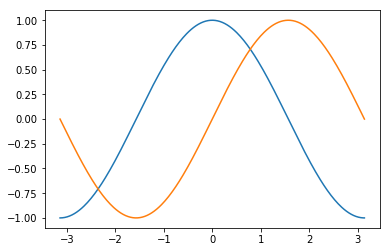

In [114]:
%matplotlib inline
from matplotlib import pyplot as plt
import numpy as np
X = np.linspace(-np.pi, np.pi, 256, endpoint=True)
C, S = np.cos(X), np.sin(X)
plt.plot(X,C)
plt.plot(X,S)

#### Customization 

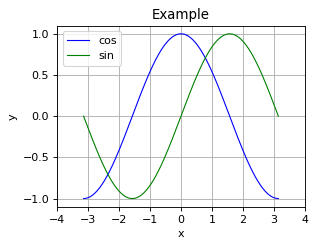

In [125]:
plt.figure(figsize=(4, 3), dpi=80)
plt.plot(X, C, color="blue", linewidth=1.0, linestyle="-", label="cos")
plt.plot(X, S, color="green", linewidth=1.0, linestyle="-", label="sin")
plt.xlim(-4.0, 4.0)
plt.xticks(np.linspace(-4, 4, 9, endpoint=True))
plt.savefig("example.png", dpi=72)
plt.grid()
plt.xlabel("x")
plt.ylabel("y")
plt.title("Example")
plt.legend(loc="best")

#### Multiple plots

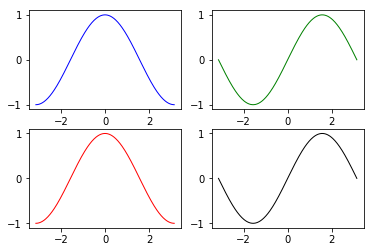

In [124]:
plt.figure(figsize=(6, 4))
plt.subplot(2, 2, 1)
plt.plot(X, C, color="blue", linewidth=1.0, linestyle="-", label="cos")
plt.subplot(2, 2, 2)
plt.plot(X, S, color="green", linewidth=1.0, linestyle="-", label="sin")
plt.subplot(2, 2, 3)
plt.plot(X, C, color="red", linewidth=1.0, linestyle="-", label="cos")
plt.subplot(2, 2, 4)
plt.plot(X, S, color="black", linewidth=1.0, linestyle="-", label="sin")
plt.show()

### Examples

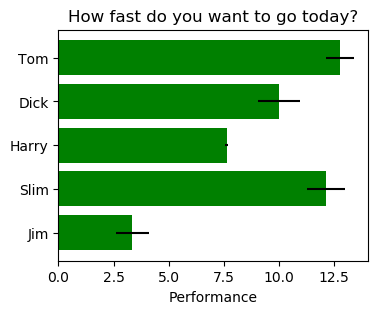

In [131]:
plt.rcdefaults()
fig, ax = plt.subplots(figsize=(4,3))
# Example data
people = ('Tom', 'Dick', 'Harry', 'Slim', 'Jim')
y_pos = np.arange(len(people))
performance = 3 + 10 * np.random.rand(len(people))
error = np.random.rand(len(people))
ax.barh(y_pos, performance, xerr=error, align='center',
        color='green', ecolor='black')
ax.set_yticks(y_pos)
ax.set_yticklabels(people)
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Performance')
ax.set_title('How fast do you want to go today?')

plt.show()

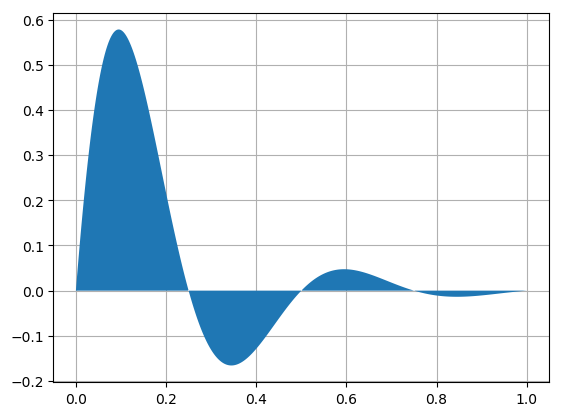

In [132]:
x = np.linspace(0, 1, 500)
y = np.sin(4 * np.pi * x) * np.exp(-5 * x)
fig, ax = plt.subplots()
ax.fill(x, y, zorder=10)
ax.grid(True, zorder=5)
plt.show()

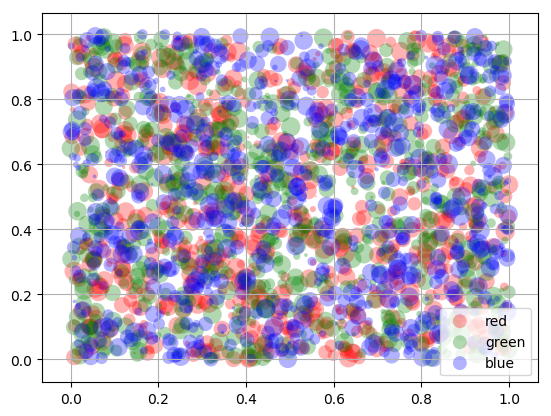

In [136]:
fig, ax = plt.subplots()
for color in ['red', 'green', 'blue']:
    n = 750
    x, y = np.random.rand(2, n)
    scale = 200.0 * np.random.rand(n)
    ax.scatter(x, y, c=color, s=scale, label=color,
               alpha=0.3, edgecolors='none')

ax.legend()
ax.grid(True)

plt.show()

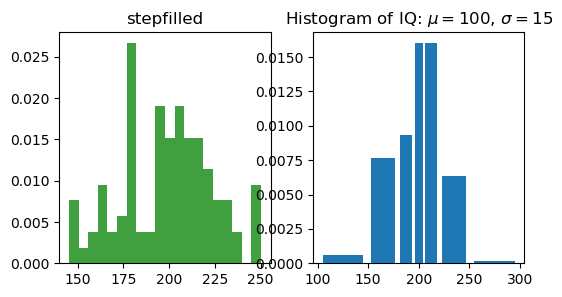

In [161]:
mu = 200
sigma = 25
x = np.random.normal(mu, sigma, size=100)
fig, (ax0, ax1) = plt.subplots(ncols=2, figsize=(6, 3))
ax0.hist(x, 20, density=1, histtype='stepfilled', facecolor='g', alpha=0.75)
ax0.set_title('stepfilled')
# Create a histogram by providing the bin edges (unequally spaced).
bins = [100, 150, 180, 195, 205, 220, 250, 300]
ax1.hist(x, bins, density=1, histtype='bar', rwidth=0.8)
ax1.set_title('unequal bins')
plt.title(r'Histogram of IQ: $\mu=100$, $\sigma=15$');

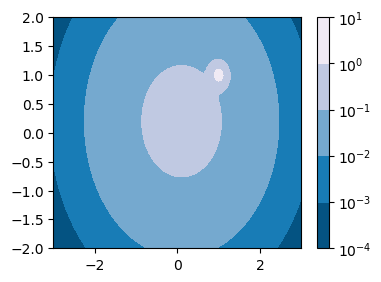

In [170]:
from matplotlib import colors, ticker, cm
from scipy.stats import multivariate_normal

N = 100
x = np.linspace(-3.0, 3.0, N)
y = np.linspace(-2.0, 2.0, N)

X, Y = np.meshgrid(x, y)
pos = np.empty(X.shape+(2,))
pos[:,:,0] = X; pos[:,:,1] = Y
# A low hump with a spike coming out of the top right.
# Needs to have z/colour axis on a log scale so we see both hump and spike.
# linear scale only shows the spike.
z = (multivariate_normal([0.1, 0.2], [[1.0, 0.],[0, 1.0]]).pdf(pos)
     + 0.1 * (multivariate_normal([1.0, 1.0],[[0.01, 0.],[0., 0.01]])).pdf(pos))
# Automatic selection of levels works; setting the
# log locator tells contourf to use a log scale:
fig, ax = plt.subplots(figsize=(4,3))
cs = ax.contourf(X, Y, z, locator=ticker.LogLocator(), cmap=cm.PuBu_r)
cbar = fig.colorbar(cs)


<img src="seaborn.png" style="width:100%">

<img src="bokeh.png" style="width:100%">

<img src="Pandas_logo.svg">

## Pandas
Pandas is a high-performance, high-level library that provides tools for data analysis.  
It relies on the concept of DataFrame: a structured collection of data organized in records. This is the same concept of ROOT's `NTuple` that you are familiar with.  
I think the name comes from R.
<img src="dataframe.jpg" style="width:50%">

In [2]:
import numpy as np
import pandas as pd

s = pd.Series( [1., 2., 3., np.nan, 5. ], index=["a","b","c","d","e"])
s

a    1.0
b    2.0
c    3.0
d    NaN
e    5.0
dtype: float64

In [11]:
df = pd.DataFrame( 
    {
        'Col1': [1.,2.,3.,4.],
        'Col2': ["a","b","c","d"],
        'Col3': [True, False, True, True]
    }
)
df

,Col1,Col2,Col3
0,1.0,a,True
1,2.0,b,False
2,3.0,c,True
3,4.0,d,True


### Reading/Saving dataframes
Pandas support reading writing to several data formats, via specialized routines, many other formats, because dataframe (with other names) are a common concept:

| Format Type  | Data Description  | Reader           | Writer          |
|--------------|-------------------|------------------|-----------------|
| text         | CSV               | `read_csv`       | `to_csv`        |
| text         | JSON              | `read_json`      | `to_json`       |
| text         | HTML              | `read_html`      | `to_html`       |
| text 	       | Local clipboard   | `read_clipboard` | `to_clipboard ` |
| binary       | MS Excel          | `read_excel`     | `to_excel`      |
| binary       | HDF5 Format       | `read_hdf` |	`to_hdf` |
| binary       | Feather Format    | `read_feather` |	`to_feather` |
| binary       | Parquet Format    | `read_parquet` |	`to_parquet` |
| binary       | Msgpack           | `read_msgpack` | `to_msgpack` |
| binary       | Stata             | `read_stata` | 	`to_stata` |
| binary       | SAS               | `read_sas` | | 	 
| binary       | Pickle Format     | `read_pickle` |	`to_pickle` |
| SQL 	       | SQL 	           | `read_sql` | `to_sql` |
| SQL 	       | Google Big Query  | `read_gbq` | 	`to_gbq` |

As you can see the physicists *ROOT* format is not natively supported. However some external software to read `TTree`s are available. For example [`root_numpy`](http://scikit-hep.org/root_numpy/), [`root_pandas`](https://github.com/scikit-hep/root_pandas), or [`uproot`](https://github.com/scikit-hep/uproot). ROOT usually comes with pre-installed `pyROOT` library (the one on the provided VM works only for python2), that offers basic functionalities.

In [12]:
df.dtypes

Col1    float64
Col2     object
Col3       bool
dtype: object

In [13]:
df.columns

Index(['Col1', 'Col2', 'Col3'], dtype='object')

In [14]:
df.index

RangeIndex(start=0, stop=4, step=1)

### View data

In [25]:

df = pd.DataFrame( {'A':np.random.randint(0,10,100), 'B': [2**x for x in np.arange(100)], 'C':"a"})
df.head()

,A,B,C
0,4,1,a
1,2,2,a
2,0,4,a
3,9,8,a
4,3,16,a


In [26]:
df.tail(2)

,A,B,C
98,5,0,a
99,9,0,a


In [27]:
df.describe()

,A,B
count,100.000000,1.000000e+02
mean,4.420000,-2.560000e+00
std,2.985419,1.070389e+18
min,0.000000,-9.223372e+18
25%,2.000000,0.000000e+00
50%,5.000000,6.144000e+03
75%,7.000000,1.717987e+11
max,9.000000,4.611686e+18


### Select data

In [86]:
dates = pd.date_range('20190527',periods=7)
df = pd.DataFrame( np.random.rand(7,4), index=dates, columns=['A','B','C','D'])
df

,A,B,C,D
2019-05-27,0.944420,0.075201,0.167932,0.017186
2019-05-28,0.245307,0.577804,0.132167,0.372844
2019-05-29,0.459021,0.087459,0.647909,0.963480
2019-05-30,0.244232,0.261606,0.109693,0.494399
2019-05-31,0.575183,0.584652,0.113913,0.117457
2019-06-01,0.190005,0.692712,0.404453,0.995082
2019-06-02,0.931300,0.489561,0.193387,0.327648


In [43]:
df['A'] # or df.A

2019-05-27    0.632271
2019-05-28    0.691208
2019-05-29    0.603331
2019-05-30    0.043723
2019-05-31    0.552101
2019-06-01    0.330455
2019-06-02    0.841736
Freq: D, Name: A, dtype: float64

In [44]:
df[0:2]

,A,B,C,D
2019-05-27,0.632271,0.218192,0.139538,0.082094
2019-05-28,0.691208,0.700231,0.730246,0.328330


In [45]:
df['20190529':'20190531']

,A,B,C,D
2019-05-29,0.603331,0.165942,0.199283,0.119786
2019-05-30,0.043723,0.162669,0.291625,0.120803
2019-05-31,0.552101,0.102359,0.702799,0.455912


In [46]:
dates

DatetimeIndex(['2019-05-27', '2019-05-28', '2019-05-29', '2019-05-30',
               '2019-05-31', '2019-06-01', '2019-06-02'],
              dtype='datetime64[ns]', freq='D')

In [47]:
df.loc[dates[2]]

A    0.603331
B    0.165942
C    0.199283
D    0.119786
Name: 2019-05-29 00:00:00, dtype: float64

In [48]:
df.loc[dates[2],['B','C']]

B    0.165942
C    0.199283
Name: 2019-05-29 00:00:00, dtype: float64

In [53]:
df.iloc[2,2:4]

C    0.199283
D    0.119786
Name: 2019-05-29 00:00:00, dtype: float64

In [55]:
df[ df>0.5 ]

,A,B,C,D
2019-05-27,0.632271,NaN,NaN,NaN
2019-05-28,0.691208,0.700231,0.730246,NaN
2019-05-29,0.603331,NaN,NaN,NaN
2019-05-30,NaN,NaN,NaN,NaN
2019-05-31,0.552101,NaN,0.702799,NaN
2019-06-01,NaN,NaN,0.868320,0.510706
2019-06-02,0.841736,NaN,0.931434,NaN


### Setting values

In [61]:
s = pd.Series( np.random.rand(7), index=dates )
s

2019-05-27    0.547899
2019-05-28    0.465972
2019-05-29    0.127552
2019-05-30    0.996297
2019-05-31    0.691513
2019-06-01    0.029567
2019-06-02    0.376882
Freq: D, dtype: float64

In [63]:
df['E'] = s
df

,A,B,C,D,E
2019-05-27,0.632271,0.218192,0.139538,0.082094,0.547899
2019-05-28,0.691208,0.700231,0.730246,0.328330,0.465972
2019-05-29,0.603331,0.165942,0.199283,0.119786,0.127552
2019-05-30,0.043723,0.162669,0.291625,0.120803,0.996297
2019-05-31,0.552101,0.102359,0.702799,0.455912,0.691513
2019-06-01,0.330455,0.227942,0.868320,0.510706,0.029567
2019-06-02,0.841736,0.088304,0.931434,0.300959,0.376882


In [64]:
df.loc[:,['C']] = 0
df

,A,B,C,D,E
2019-05-27,0.632271,0.218192,0.0,0.082094,0.547899
2019-05-28,0.691208,0.700231,0.0,0.328330,0.465972
2019-05-29,0.603331,0.165942,0.0,0.119786,0.127552
2019-05-30,0.043723,0.162669,0.0,0.120803,0.996297
2019-05-31,0.552101,0.102359,0.0,0.455912,0.691513
2019-06-01,0.330455,0.227942,0.0,0.510706,0.029567
2019-06-02,0.841736,0.088304,0.0,0.300959,0.376882


### Operations

In [68]:
df.mean()

A    0.527832
B    0.237948
C    0.000000
D    0.274084
E    0.462240
dtype: float64

In [69]:
df.mean(axis=1)

2019-05-27    0.296091
2019-05-28    0.437148
2019-05-29    0.203322
2019-05-30    0.264698
2019-05-31    0.360377
2019-06-01    0.219734
2019-06-02    0.321576
Freq: D, dtype: float64

## Merging dataframes

In [76]:
df1 = pd.DataFrame( np.random.rand(7,2), index=dates, columns=['A','B'])
df2 = pd.DataFrame( np.random.rand(7,3), index=dates, columns=['C','D','E'])
pd.concat([df1,df2],sort=False)

,A,B,C,D,E
2019-05-27,0.012169,0.252402,NaN,NaN,NaN
2019-05-28,0.420066,0.163832,NaN,NaN,NaN
2019-05-29,0.709032,0.134392,NaN,NaN,NaN
2019-05-30,0.245606,0.952309,NaN,NaN,NaN
2019-05-31,0.750060,0.851338,NaN,NaN,NaN
2019-06-01,0.334091,0.825410,NaN,NaN,NaN
2019-06-02,0.222300,0.897779,NaN,NaN,NaN
2019-05-27,NaN,NaN,0.781323,0.624619,0.382809
2019-05-28,NaN,NaN,0.932316,0.051429,0.823951
2019-05-29,NaN,NaN,0.246817,0.021852,0.699723


In [78]:
pd.concat([df1,df2],axis=1,join='inner')

,A,B,C,D,E
2019-05-27,0.012169,0.252402,0.781323,0.624619,0.382809
2019-05-28,0.420066,0.163832,0.932316,0.051429,0.823951
2019-05-29,0.709032,0.134392,0.246817,0.021852,0.699723
2019-05-30,0.245606,0.952309,0.700137,0.231148,0.373396
2019-05-31,0.750060,0.851338,0.340692,0.371376,0.751349
2019-06-01,0.334091,0.825410,0.567121,0.771248,0.712765
2019-06-02,0.222300,0.897779,0.970691,0.146501,0.218353


### Grouping

In [81]:
s = pd.Series( ["a","b","a","c","a","c","b"], index=dates)
df['E']=s
df

,A,B,C,D,E
2019-05-27,0.632271,0.218192,0.0,0.082094,a
2019-05-28,0.691208,0.700231,0.0,0.328330,b
2019-05-29,0.603331,0.165942,0.0,0.119786,a
2019-05-30,0.043723,0.162669,0.0,0.120803,c
2019-05-31,0.552101,0.102359,0.0,0.455912,a
2019-06-01,0.330455,0.227942,0.0,0.510706,c
2019-06-02,0.841736,0.088304,0.0,0.300959,b


In [82]:
df.groupby('E').sum()

,A,B,C,D
E,,,,
a,1.787704,0.486493,0.0,0.657791
b,1.532944,0.788535,0.0,0.629290
c,0.374178,0.390611,0.0,0.631508


### Pivot table

In [105]:
dates = pd.date_range('20190527',periods=6, name='date')
df = pd.DataFrame( np.random.rand(6,3), index=dates, columns=['A','B','C'])
df['D'] = pd.Series(["a","a","b","b","c","c"],index=dates)
df['E'] = pd.Series(["one","two","one","two","one","two"],index=dates)
df

,A,B,C,D,E
date,,,,,
2019-05-27,0.474915,0.196110,0.301641,a,one
2019-05-28,0.057920,0.349846,0.670458,a,two
2019-05-29,0.878578,0.884794,0.904183,b,one
2019-05-30,0.456244,0.917951,0.879430,b,two
2019-05-31,0.592064,0.925768,0.601040,c,one
2019-06-01,0.403849,0.445142,0.004900,c,two


In [106]:
pd.pivot_table(df, values=['A','B','C'], index=['D','E'])

A         B         C
D E                                
a one  0.474915  0.196110  0.301641
  two  0.057920  0.349846  0.670458
b one  0.878578  0.884794  0.904183
  two  0.456244  0.917951  0.879430
c one  0.592064  0.925768  0.601040
  two  0.403849  0.445142  0.004900

### Plotting data

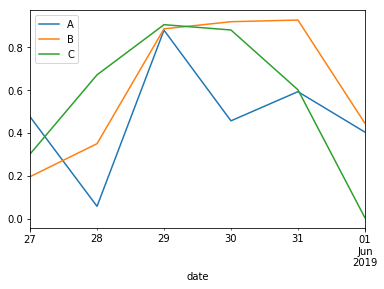

In [107]:
%matplotlib inline
df.plot()